In [1]:
from sklearn.feature_extraction.text import CountVectorizer

texts = [
    "I love machine learning",
    "Machine learning is amazing",
    "I love coding"
]

vectorizer = CountVectorizer()
bow = vectorizer.fit_transform(texts)

print("Features:")
print(vectorizer.get_feature_names_out())

print("\nBoW Matrix:")
print(bow.toarray())

Features:
['amazing' 'coding' 'is' 'learning' 'love' 'machine']

BoW Matrix:
[[0 0 0 1 1 1]
 [1 0 1 1 0 1]
 [0 1 0 0 1 0]]


In [2]:
from sklearn.feature_extraction.text import CountVectorizer

corpus = [
    "This is the first document.",
    "This document is the second document.",
    "And this is the third one.",
    "Is this the first document?"
]

vectorizer = CountVectorizer(ngram_range=(2, 2))
X = vectorizer.fit_transform(corpus)

print(vectorizer.get_feature_names_out())
print(X.toarray())

['and this' 'document is' 'first document' 'is the' 'is this'
 'second document' 'the first' 'the second' 'the third' 'third one'
 'this document' 'this is' 'this the']
[[0 0 1 1 0 0 1 0 0 0 0 1 0]
 [0 1 0 1 0 1 0 1 0 0 1 0 0]
 [1 0 0 1 0 0 0 0 1 1 0 1 0]
 [0 0 1 0 1 0 1 0 0 0 0 0 1]]


In [3]:
from sklearn.feature_extraction.text import CountVectorizer

corpus = [
    "This is the first document.",
    "This document is the second document.",
    "And this is the third one.",
    "Is this the first document?"
]

vectorizer = CountVectorizer(ngram_range=(1, 2))
X = vectorizer.fit_transform(corpus)

print(vectorizer.get_feature_names_out())
print(X.toarray())

['and' 'and this' 'document' 'document is' 'first' 'first document' 'is'
 'is the' 'is this' 'one' 'second' 'second document' 'the' 'the first'
 'the second' 'the third' 'third' 'third one' 'this' 'this document'
 'this is' 'this the']
[[0 0 1 0 1 1 1 1 0 0 0 0 1 1 0 0 0 0 1 0 1 0]
 [0 0 2 1 0 0 1 1 0 0 1 1 1 0 1 0 0 0 1 1 0 0]
 [1 1 0 0 0 0 1 1 0 1 0 0 1 0 0 1 1 1 1 0 1 0]
 [0 0 1 0 1 1 1 0 1 0 0 0 1 1 0 0 0 0 1 0 0 1]]


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

texts = [
    "I love machine learning",
    "Machine learning is amazing",
    "I love coding"
]

tfidf = TfidfVectorizer()
X = tfidf.fit_transform(texts)

print("Features:")
print(tfidf.get_feature_names_out())

print("\nTF-IDF Matrix:")
print(X.toarray())

Features:
['amazing' 'coding' 'is' 'learning' 'love' 'machine']

TF-IDF Matrix:
[[0.         0.         0.         0.57735027 0.57735027 0.57735027]
 [0.5628291  0.         0.5628291  0.42804604 0.         0.42804604]
 [0.         0.79596054 0.         0.         0.60534851 0.        ]]


In [5]:
text1 = set("machine learning is fun".split())
text2 = set("learning about machine intelligence".split())

jaccard = len(text1 & text2) / len(text1 | text2)

print("Jaccard Similarity:", jaccard)

Jaccard Similarity: 0.3333333333333333


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

texts = [
    "machine learning is fun",
    "learning about machine intelligence"
]

vectorizer = TfidfVectorizer()
vectors = vectorizer.fit_transform(texts)

similarity = cosine_similarity(vectors[0:1], vectors[1:2])

print("Cosine Similarity:", similarity[0][0])

Cosine Similarity: 0.3360969272762575


In [7]:
!pip install textblob

In [8]:
from textblob import TextBlob

review = "The service was excellent and the staff was friendly."

blob = TextBlob(review)

print("Polarity:", blob.sentiment.polarity)
print("Subjectivity:", blob.sentiment.subjectivity)

Polarity: 0.6875
Subjectivity: 0.75


In [9]:
!pip install wordcloud

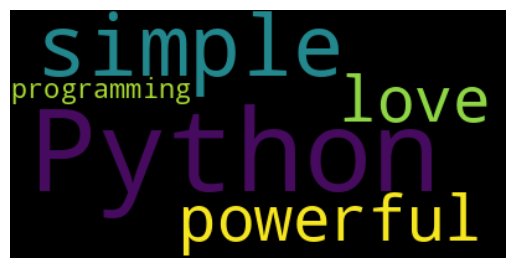

In [10]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text = "Python is simple and powerful. I love Python programming!"

wordcloud = WordCloud().generate(text)

plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

In [11]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# Training text
text = """I love learning about machine learning and deep learning.
Learning is fun and powerful."""

# Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

print("Word Index:")
print(tokenizer.word_index)

# Convert text to sequences
tokens = tokenizer.texts_to_sequences([text])[0]

sequences = []

for i in range(1, len(tokens)):
    sequences.append(tokens[:i+1])

print("\nSequences:")
for seq in sequences:
    print(seq)

# Padding
max_len = max(len(seq) for seq in sequences)

sequences = pad_sequences(
    sequences,
    maxlen=max_len,
    padding='pre'
)

print("\nPadded Sequences:")
print(sequences)

# X and y
sequences = np.array(sequences)

X = sequences[:, :-1]
y = sequences[:, -1]

# One-hot encoding
total_words = len(tokenizer.word_index) + 1

y = to_categorical(
    y,
    num_classes=total_words
)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

# Build LSTM model
model = Sequential([
    Embedding(total_words, 10, input_length=X.shape[1]),
    LSTM(100),
    Dense(total_words, activation='softmax')
])

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

# Train
model.fit(X, y, epochs=200, verbose=1)

# Generate text
seed_text = "machine"
next_words = 3

for _ in range(next_words):

    token_list = tokenizer.texts_to_sequences([seed_text])[0]

    token_list = pad_sequences(
        [token_list],
        maxlen=X.shape[1],
        padding='pre'
    )

    predicted = model.predict(token_list, verbose=0)

    predicted_word = tokenizer.index_word[
        np.argmax(predicted)
    ]

    seed_text += " " + predicted_word

print("\nGenerated Text:", seed_text)


Word Index:
{'learning': 1, 'and': 2, 'i': 3, 'love': 4, 'about': 5, 'machine': 6, 'deep': 7, 'is': 8, 'fun': 9, 'powerful': 10}

Sequences:
[3, 4]
[3, 4, 1]
[3, 4, 1, 5]
[3, 4, 1, 5, 6]
[3, 4, 1, 5, 6, 1]
[3, 4, 1, 5, 6, 1, 2]
[3, 4, 1, 5, 6, 1, 2, 7]
[3, 4, 1, 5, 6, 1, 2, 7, 1]
[3, 4, 1, 5, 6, 1, 2, 7, 1, 1]
[3, 4, 1, 5, 6, 1, 2, 7, 1, 1, 8]
[3, 4, 1, 5, 6, 1, 2, 7, 1, 1, 8, 9]
[3, 4, 1, 5, 6, 1, 2, 7, 1, 1, 8, 9, 2]
[3, 4, 1, 5, 6, 1, 2, 7, 1, 1, 8, 9, 2, 10]

Padded Sequences:
[[ 0  0  0  0  0  0  0  0  0  0  0  0  3  4]
 [ 0  0  0  0  0  0  0  0  0  0  0  3  4  1]
 [ 0  0  0  0  0  0  0  0  0  0  3  4  1  5]
 [ 0  0  0  0  0  0  0  0  0  3  4  1  5  6]
 [ 0  0  0  0  0  0  0  0  3  4  1  5  6  1]
 [ 0  0  0  0  0  0  0  3  4  1  5  6  1  2]
 [ 0  0  0  0  0  0  3  4  1  5  6  1  2  7]
 [ 0  0  0  0  0  3  4  1  5  6  1  2  7  1]
 [ 0  0  0  0  3  4  1  5  6  1  2  7  1  1]
 [ 0  0  0  3  4  1  5  6  1  2  7  1  1  8]
 [ 0  0  3  4  1  5  6  1  2  7  1  1  8  9]
 [ 0  3  4  1  5  6

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.0000e+00 - loss: 2.4010
Epoch 2/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.3077 - loss: 2.3961
Epoch 3/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.3077 - loss: 2.3914
Epoch 4/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.3077 - loss: 2.3867
Epoch 5/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.3077 - loss: 2.3817
Epoch 6/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.3077 - loss: 2.3762
Epoch 7/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.3077 - loss: 2.3699
Epoch 8/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.3077 - loss: 2.3625
Epoch 9/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.3077 - loss: 2.3538
Epoch 10/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.3077 - loss: 2.3432
Epoch 11/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.3077 - loss: 2.3303
Epoch 12/200
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.3077 - 